In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os


Disease rows: 600 | Teeth rows: 600


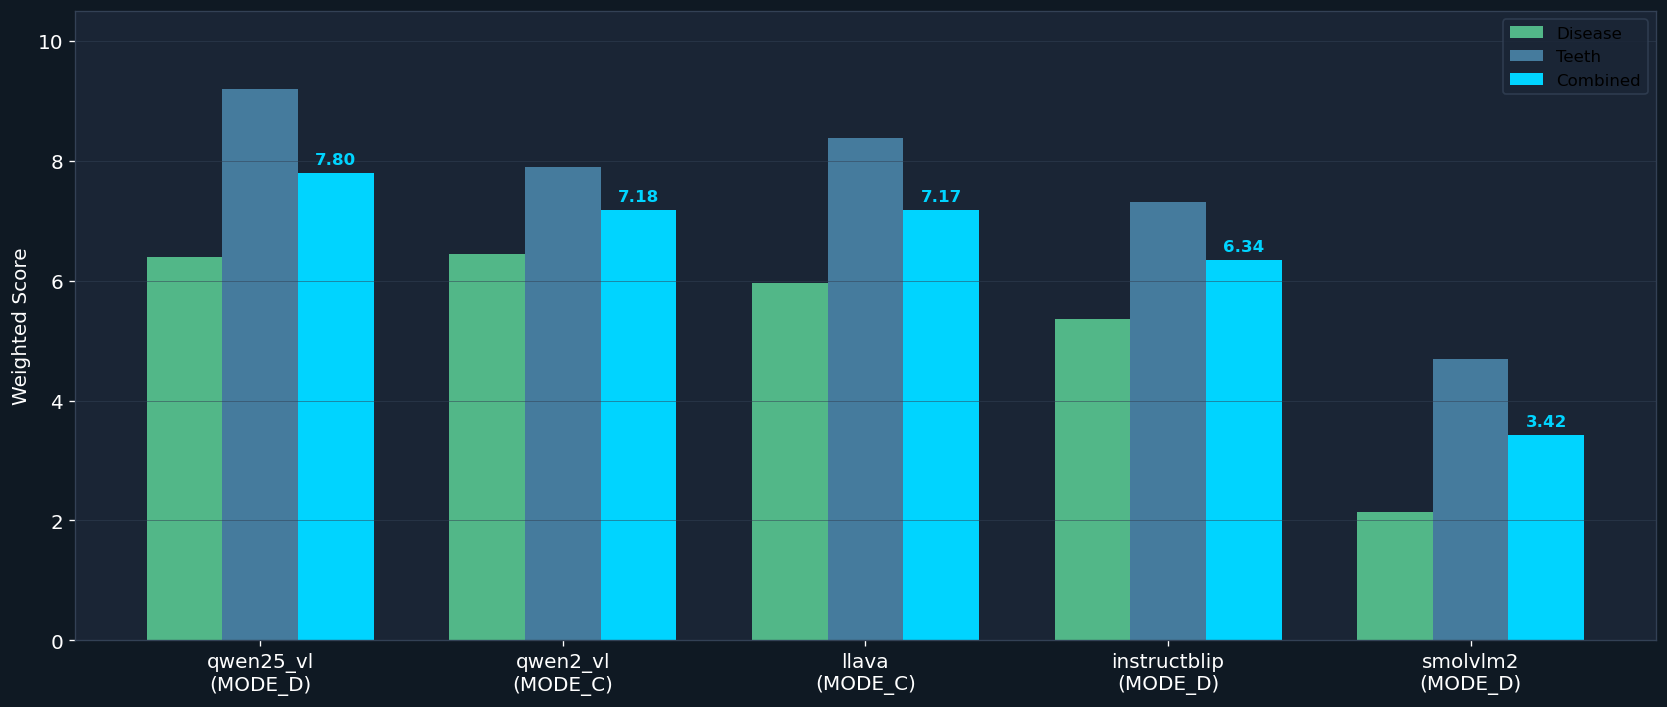

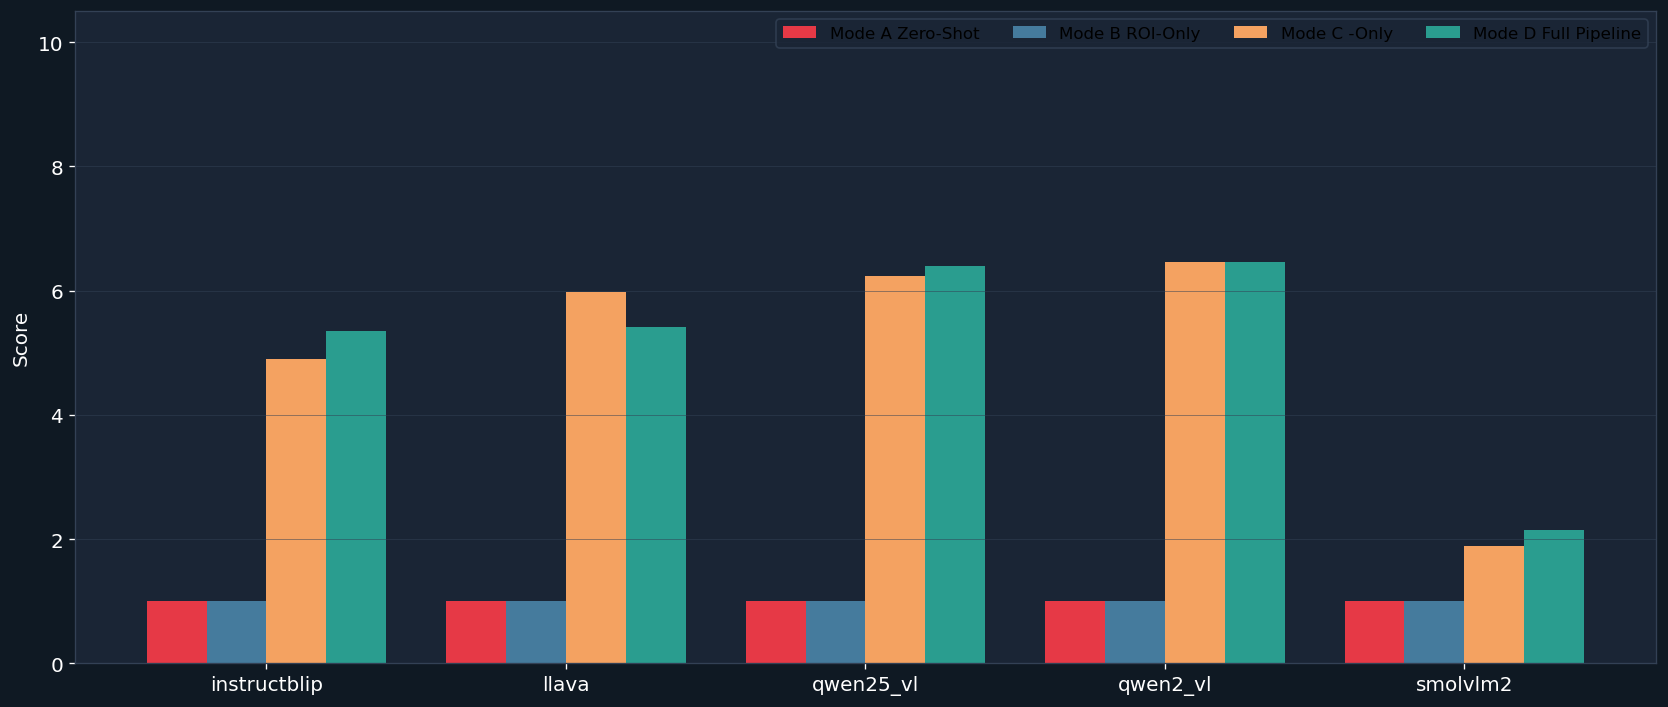

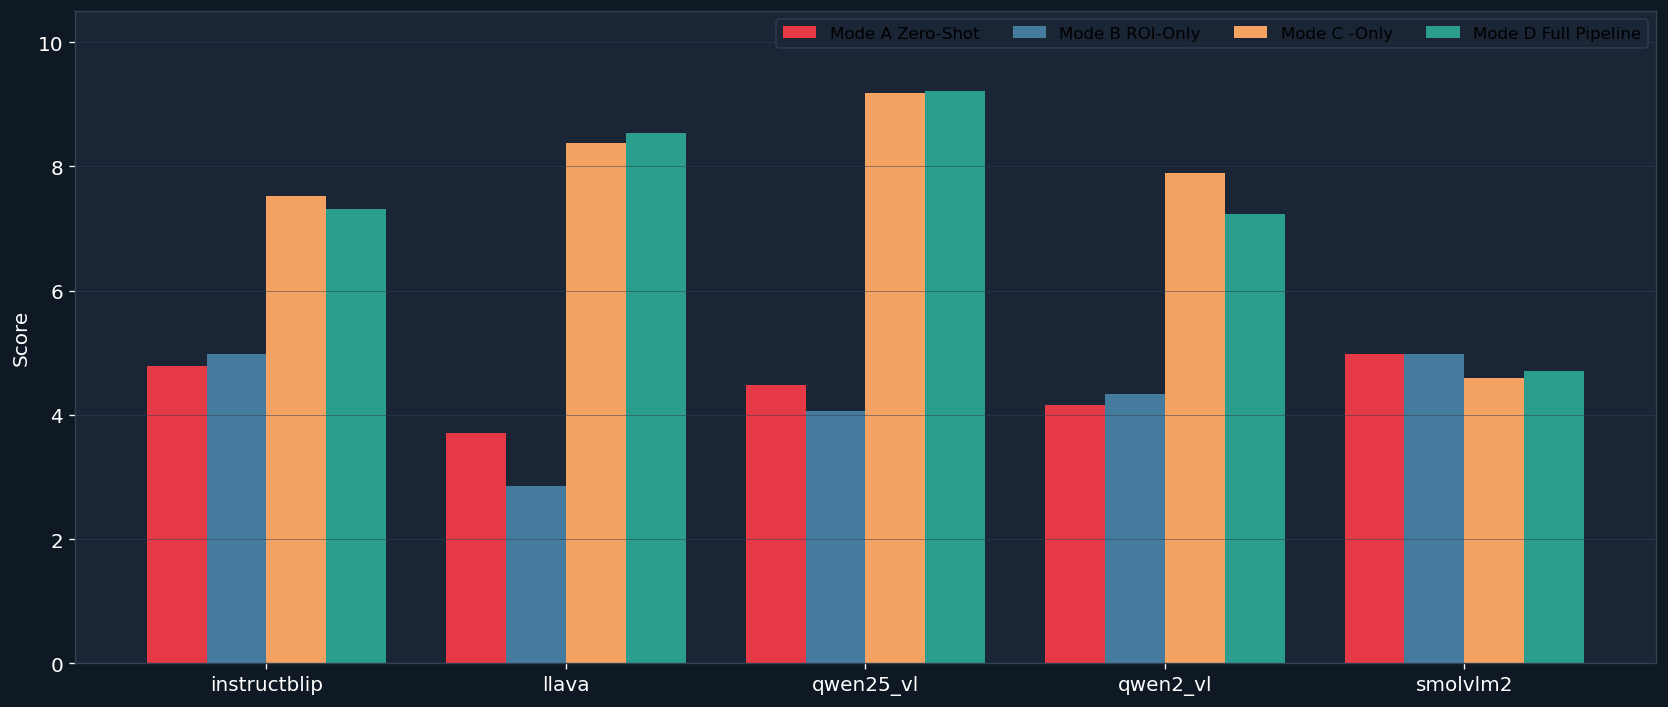

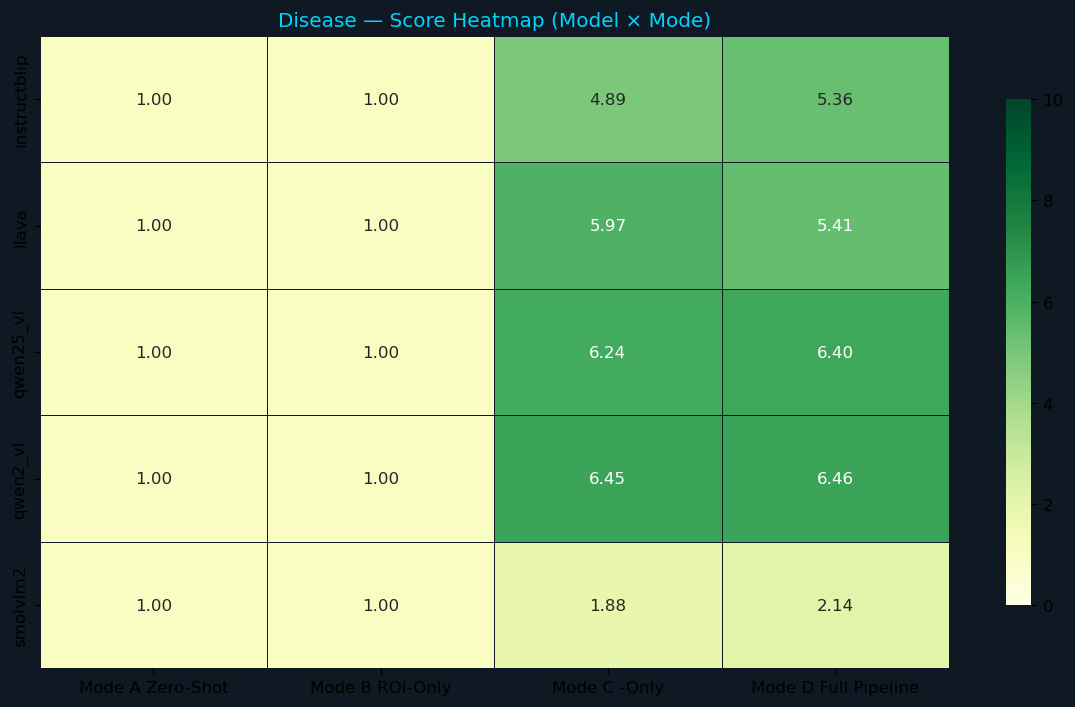

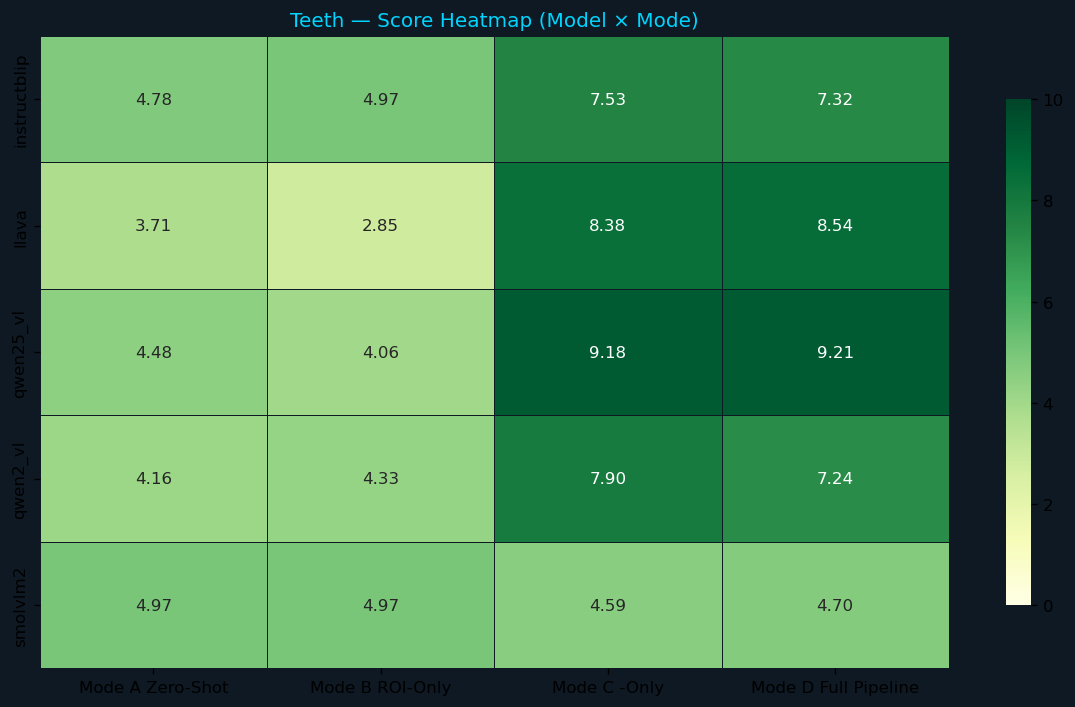

In [2]:
# =========================================================
# VISUALIZATION PIPELINE — VLM EVALUATION RESULTS
# =========================================================

# ── Setup ────────────────────────────────────────────────
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
plt.rcParams["figure.dpi"] = 120

# ── Paths ────────────────────────────────────────────────
DISEASE_JSON = "disease_results_raw.json"
TEETH_JSON   = "teeth_results_raw.json"

# ── Configuration ────────────────────────────────────────
MODES = ["mode_a", "mode_b", "mode_c", "mode_d"]

MODE_LABELS = {
    "mode_a": "Mode A\nZero-Shot",
    "mode_b": "Mode B\nROI-Only",
    "mode_c": "Mode C\n-Only",
    "mode_d": "Mode D\nFull Pipeline",
}

MODE_COLORS = {
    "mode_a": "#E63946",
    "mode_b": "#457B9D",
    "mode_c": "#F4A261",
    "mode_d": "#2A9D8F",
}

DISEASE_METRICS = [
    "disease_type_accuracy",
    "fdi_localization",
    "anatomical_precision",
    "gt_recall",
]

TEETH_METRICS = [
    "missing_recall",
    "false_absence",
    "missing_specificity",
]

# ── Styling ──────────────────────────────────────────────
DARK_BG = "#0F1923"
MID_BG  = "#1A2535"
ACCENT  = "#00D4FF"


# =========================================================
# DATA LOADING
# =========================================================
def load_json(path):
    if not os.path.exists(path):
        print(f"⚠️ Missing file: {path}")
        return {}
    with open(path, "r") as f:
        return json.load(f)


# =========================================================
# DATA FLATTENING
# =========================================================
def flatten(raw, task_type):
    metrics = DISEASE_METRICS if task_type == "disease" else TEETH_METRICS
    rows = []

    for img, img_data in raw.items():
        for model, model_data in img_data.items():
            if not isinstance(model_data, dict):
                continue

            for mode, mode_data in model_data.items():
                if mode not in MODES or not isinstance(mode_data, dict):
                    continue

                eval_data = mode_data.get(task_type, {})
                if not eval_data:
                    continue

                row = {
                    "image": img,
                    "model": model,
                    "mode": mode,
                    "weighted_score": eval_data.get("weighted_score", 0.0),
                }

                for m in metrics:
                    row[m] = eval_data.get("scores", {}).get(m, np.nan)

                rows.append(row)

    return pd.DataFrame(rows)


# =========================================================
# PLOTTING UTILITIES
# =========================================================
def style_ax(ax, title="", xlabel="", ylabel="", ylim=None):
    ax.set_facecolor(MID_BG)
    ax.grid(axis="y", color="#334155", linewidth=0.5, alpha=0.6)

    ax.tick_params(colors="white", labelsize=12)
    ax.xaxis.label.set_color("white")
    ax.yaxis.label.set_color("white")

    for spine in ax.spines.values():
        spine.set_edgecolor("#334155")

    if title:
        ax.set_title(title, color=ACCENT, fontsize=11, fontweight="bold")
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12)
    if ylim:
        ax.set_ylim(ylim)


def show(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)


# =========================================================
# LOAD DATA
# =========================================================
ddf = flatten(load_json(DISEASE_JSON), "disease")
tdf = flatten(load_json(TEETH_JSON), "teeth")

print(f"Disease rows: {len(ddf)} | Teeth rows: {len(tdf)}")


# =========================================================
# 1 — COMBINED SCORE (BEST MODE PER MODEL)
# =========================================================
if not ddf.empty and not tdf.empty:

    disease = ddf.groupby(["model", "mode"])["weighted_score"].mean()
    teeth   = tdf.groupby(["model", "mode"])["weighted_score"].mean()

    comb = pd.concat([disease.rename("disease"),
                      teeth.rename("teeth")], axis=1).dropna()

    comb["combined"] = (comb["disease"] + comb["teeth"]) / 2
    comb = comb.reset_index()

    best = comb.loc[comb.groupby("model")["combined"].idxmax()]
    best = best.sort_values("combined", ascending=False)

    fig, ax = plt.subplots(figsize=(14, 6), facecolor=DARK_BG)

    x = np.arange(len(best))
    w = 0.25

    ax.bar(x - w, best["disease"],  w, color="#52B788", label="Disease")
    ax.bar(x,     best["teeth"],    w, color="#457B9D", label="Teeth")
    ax.bar(x + w, best["combined"], w, color=ACCENT,    label="Combined")

    for i, r in enumerate(best.itertuples()):
        ax.text(i + w, r.combined + 0.15, f"{r.combined:.2f}",
                ha="center", color=ACCENT, fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{r.model}\n({r.mode.upper()})" for r in best.itertuples()],
        fontsize=20, ha="center", color="white"
    )

    style_ax(ax,
             ylabel="Weighted Score", ylim=(0, 10.5))

    ax.legend(facecolor=MID_BG, edgecolor="#334155")
    show(fig)


# =========================================================
# 2 — DISEASE SCORES BY MODE
# =========================================================
if not ddf.empty:

    pivot = ddf.groupby(["model", "mode"])["weighted_score"].mean().unstack(fill_value=0)

    for m in MODES:
        if m not in pivot.columns:
            pivot[m] = 0
    pivot = pivot[MODES]

    fig, ax = plt.subplots(figsize=(14, 6), facecolor=DARK_BG)

    x = np.arange(len(pivot))
    w = 0.2

    for i, m in enumerate(MODES):
        ax.bar(x + i*w, pivot[m], w, color=MODE_COLORS[m],
               label=MODE_LABELS[m].replace("\n", " "))

    ax.set_xticks(x + 1.5*w)
    ax.set_xticklabels(pivot.index, fontsize=20, color="white")

    style_ax(ax,
             ylabel="Score", ylim=(0, 10.5))

    ax.legend(ncol=4, facecolor=MID_BG, edgecolor="#334155")
    show(fig)


# =========================================================
# 3 — TEETH SCORES BY MODE
# =========================================================
if not tdf.empty:

    pivot = tdf.groupby(["model", "mode"])["weighted_score"].mean().unstack(fill_value=0)

    for m in MODES:
        if m not in pivot.columns:
            pivot[m] = 0
    pivot = pivot[MODES]

    fig, ax = plt.subplots(figsize=(14, 6), facecolor=DARK_BG)

    x = np.arange(len(pivot))
    w = 0.2

    for i, m in enumerate(MODES):
        ax.bar(x + i*w, pivot[m], w, color=MODE_COLORS[m],
               label=MODE_LABELS[m].replace("\n", " "))

    ax.set_xticks(x + 1.5*w)
    ax.set_xticklabels(pivot.index, fontsize=20, color="white")

    style_ax(ax,
             ylabel="Score", ylim=(0, 10.5))

    ax.legend(ncol=4, facecolor=MID_BG, edgecolor="#334155")
    show(fig)


# =========================================================
# 4 — HEATMAP (DISEASE)
# =========================================================
if not ddf.empty:

    pivot = ddf.groupby(["model", "mode"])["weighted_score"].mean().unstack(fill_value=0)
    pivot = pivot.reindex(columns=MODES, fill_value=0)
    pivot.columns = [MODE_LABELS[m].replace("\n", " ") for m in MODES]

    fig, ax = plt.subplots(figsize=(10, max(4, len(pivot)*0.8 + 2)), facecolor=DARK_BG)

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="YlGn",
        vmin=0,
        vmax=10,
        linewidths=0.5,
        linecolor="#0F1923",
        cbar_kws={"shrink": 0.8},
        ax=ax
    )

    ax.set_title("Disease — Score Heatmap (Model × Mode)", color=ACCENT)
    ax.set_xlabel("")
    ax.set_ylabel("")
    show(fig)


# =========================================================
# 5 — HEATMAP (TEETH)
# =========================================================
if not tdf.empty:

    pivot = tdf.groupby(["model", "mode"])["weighted_score"].mean().unstack(fill_value=0)
    pivot = pivot.reindex(columns=MODES, fill_value=0)
    pivot.columns = [MODE_LABELS[m].replace("\n", " ") for m in MODES]

    fig, ax = plt.subplots(figsize=(10, max(4, len(pivot)*0.8 + 2)), facecolor=DARK_BG)

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        cmap="YlGn",
        vmin=0,
        vmax=10,
        linewidths=0.5,
        linecolor="#0F1923",
        cbar_kws={"shrink": 0.8},
        ax=ax
    )

    ax.set_title("Teeth — Score Heatmap (Model × Mode)", color=ACCENT)
    ax.set_xlabel("")
    ax.set_ylabel("")
    show(fig)

Disease rows: 600 | Teeth rows: 600

EPS figures will be saved to:
eps_figures


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


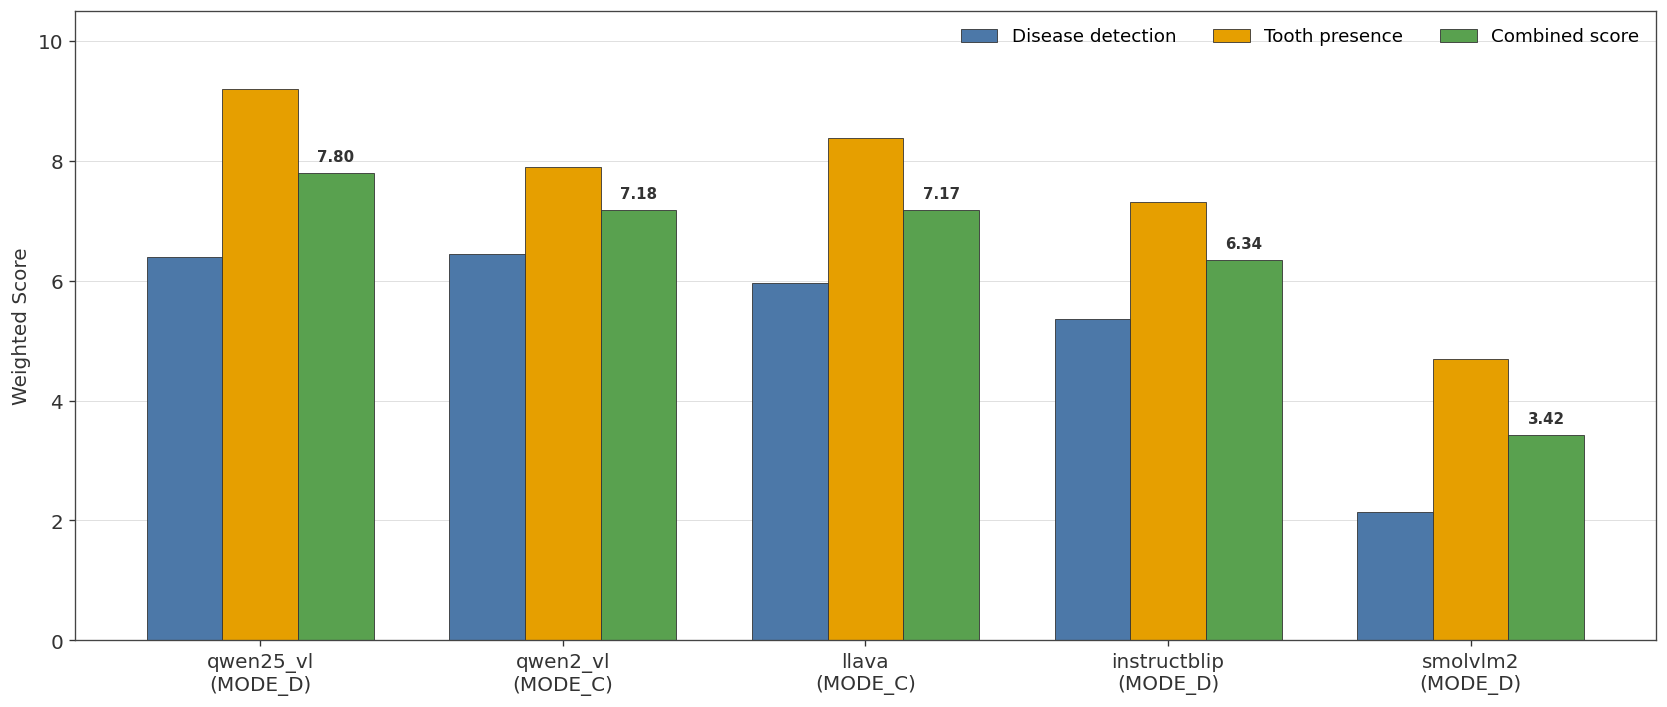

Saved EPS: eps_figures\combined_score.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


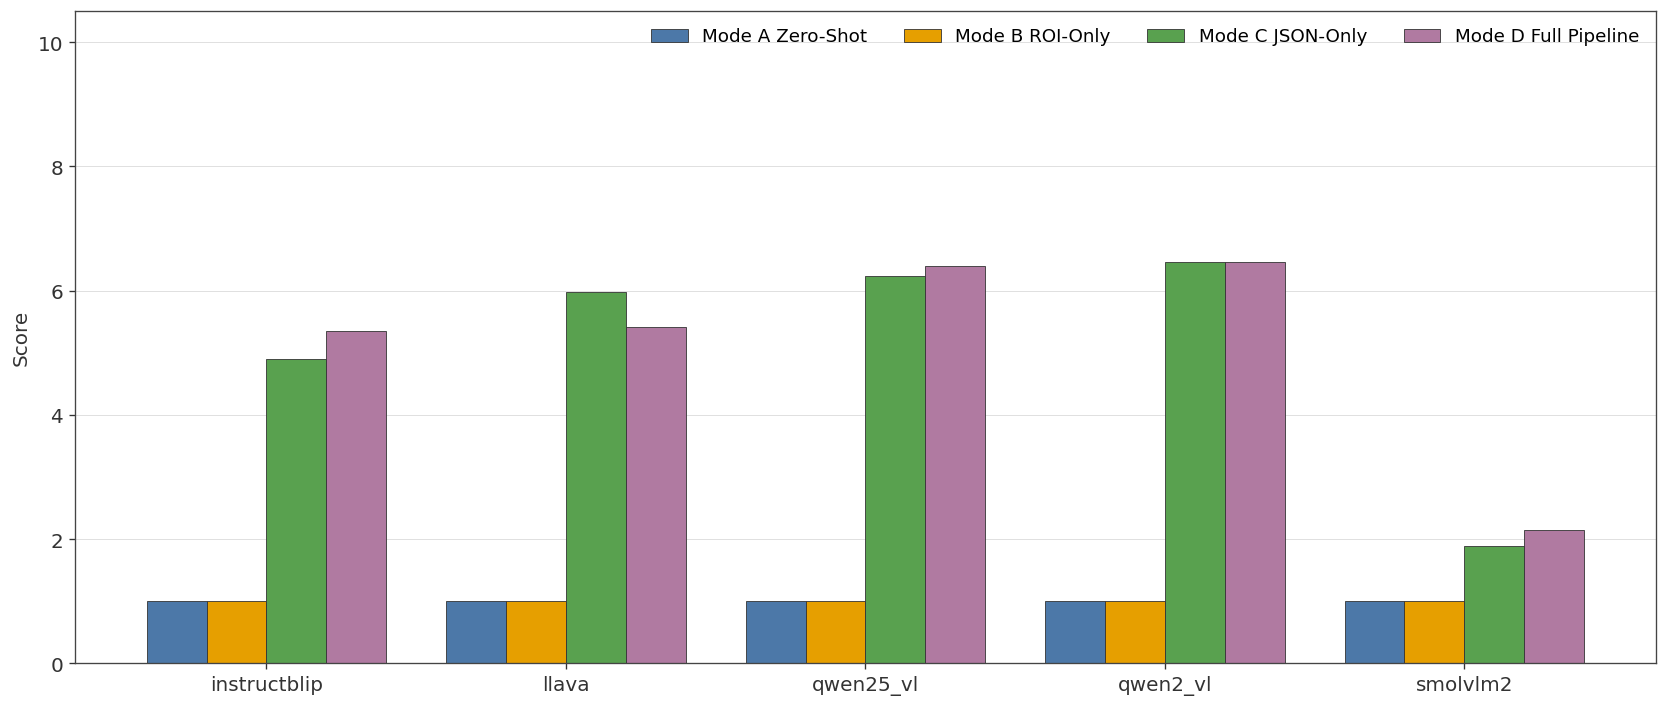

Saved EPS: eps_figures\disease_scores_by_mode.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


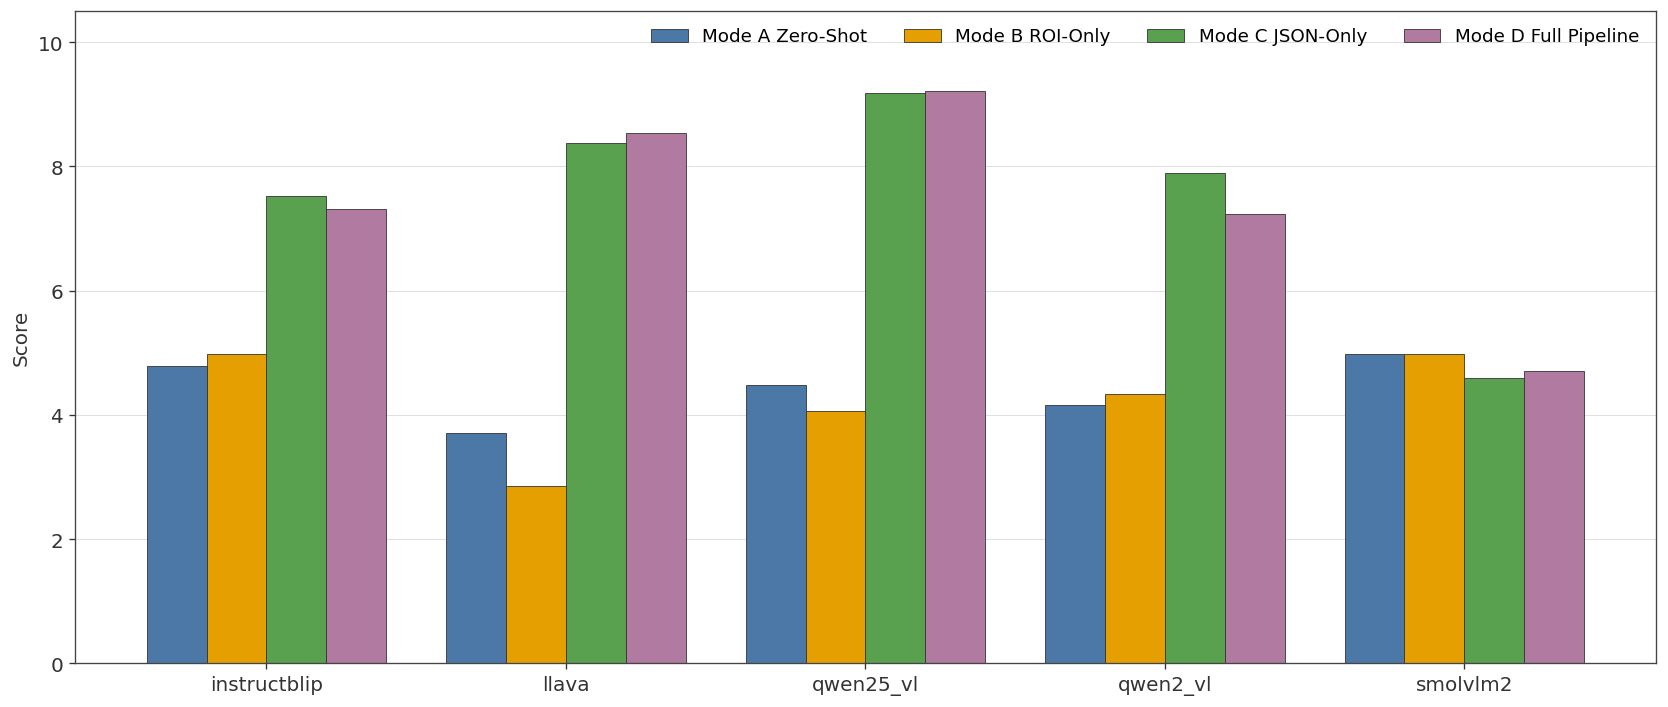

Saved EPS: eps_figures\teeth_scores_by_mode.eps


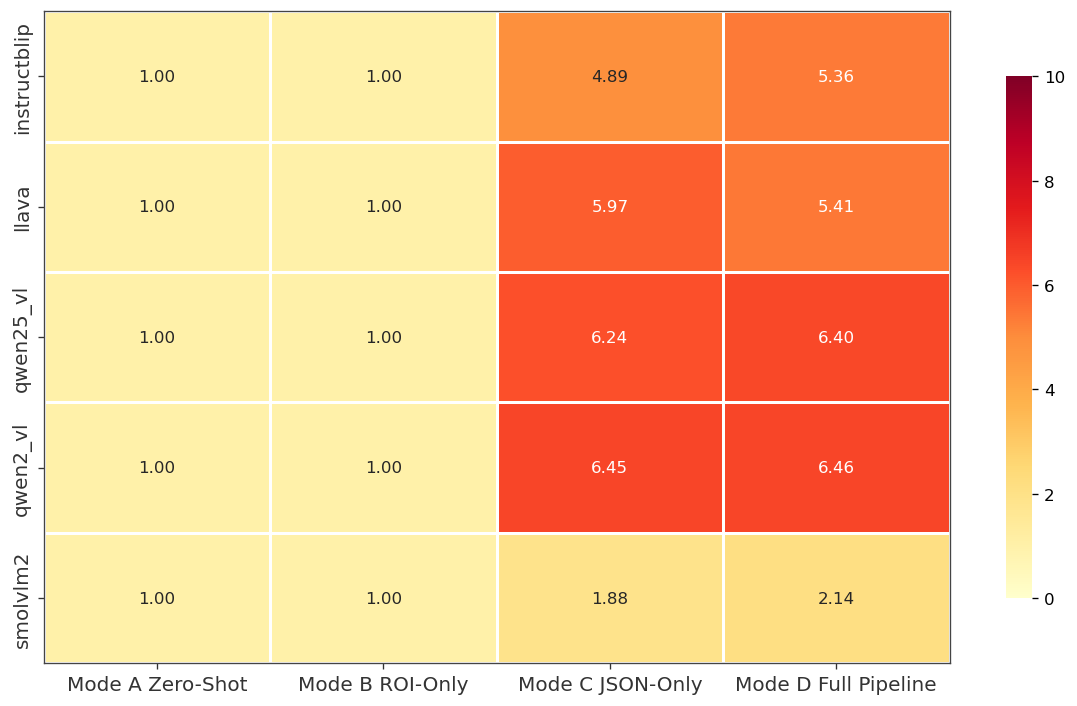

Saved EPS: eps_figures\disease_heatmap.eps


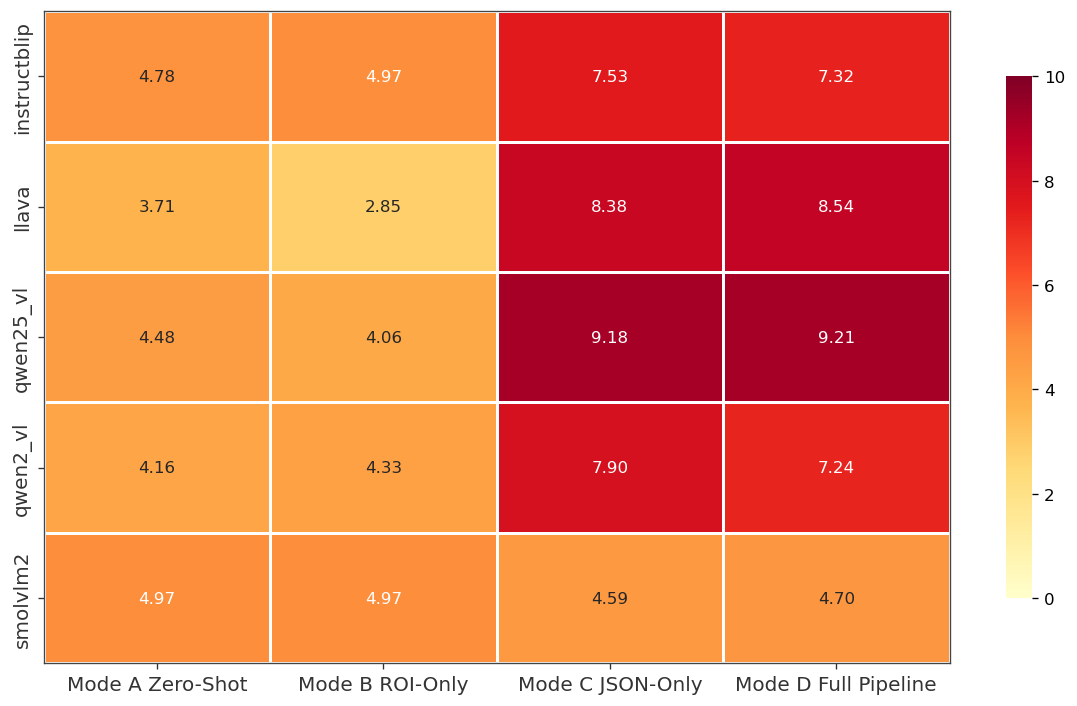

Saved EPS: eps_figures\teeth_heatmap.eps

GENERATED EPS FIGURES
combined_score.eps                  36.5 KB
disease_heatmap.eps                 541.5 KB
disease_scores_by_mode.eps          32.0 KB
teeth_heatmap.eps                   541.5 KB
teeth_scores_by_mode.eps            32.0 KB


In [3]:
# =========================================================
# VISUALIZATION PIPELINE — VLM EVALUATION RESULTS
# Scientific-paper style
# White background + borders + EPS export
# =========================================================

# ── Setup ─────────────────────────────────────────────────

import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.family"] = "DejaVu Sans"


# =========================================================
# PATHS
# =========================================================

DISEASE_JSON = "disease_results_raw.json"
TEETH_JSON   = "teeth_results_raw.json"

# Folder for EPS figures
OUTPUT_DIR = "eps_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# =========================================================
# CONFIGURATION
# =========================================================

MODES = [
    "mode_a",
    "mode_b",
    "mode_c",
    "mode_d"
]

MODE_LABELS = {
    "mode_a": "Mode A\nZero-Shot",
    "mode_b": "Mode B\nROI-Only",
    "mode_c": "Mode C\nJSON-Only",
    "mode_d": "Mode D\nFull Pipeline",
}

# Scientific / publication-friendly palette
MODE_COLORS = {
    "mode_a": "#4C78A8",   # muted blue
    "mode_b": "#E69F00",   # orange
    "mode_c": "#59A14F",   # green
    "mode_d": "#B07AA1",   # purple
}

DISEASE_METRICS = [
    "disease_type_accuracy",
    "fdi_localization",
    "anatomical_precision",
    "gt_recall",
]

TEETH_METRICS = [
    "missing_recall",
    "false_absence",
    "missing_specificity",
]


# =========================================================
# SCIENTIFIC PAPER STYLE
# =========================================================

def style_ax(
    ax,
    title="",
    xlabel="",
    ylabel="",
    ylim=None
):

    # White background
    ax.set_facecolor("white")

    # Light horizontal grid
    ax.grid(
        axis="y",
        color="#D9D9D9",
        linewidth=0.6,
        alpha=0.8
    )

    # Put grid behind bars
    ax.set_axisbelow(True)

    # Tick styling
    ax.tick_params(
        axis="both",
        colors="#333333",
        labelsize=12
    )

    # Axis labels
    ax.xaxis.label.set_color("#333333")
    ax.yaxis.label.set_color("#333333")

    # Visible border around every plot
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#444444")
        spine.set_linewidth(0.8)

    # Title
    if title:
        ax.set_title(
            title,
            color="#222222",
            fontsize=11,
            fontweight="bold",
            pad=10
        )

    if xlabel:
        ax.set_xlabel(
            xlabel,
            fontsize=12
        )

    if ylabel:
        ax.set_ylabel(
            ylabel,
            fontsize=12
        )

    if ylim:
        ax.set_ylim(ylim)


def style_heatmap(ax, title=""):

    # Visible border around heatmap
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("#444444")
        spine.set_linewidth(0.8)

    ax.tick_params(
        axis="both",
        colors="#333333",
        labelsize=12
    )

    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold",
        color="#222222",
        pad=10
    )

    ax.set_xlabel("")
    ax.set_ylabel("")


# =========================================================
# DISPLAY + EPS EXPORT
# =========================================================

def show(fig, filename):

    fig.tight_layout()

    # EPS output path
    output_path = os.path.join(
        OUTPUT_DIR,
        f"{filename}.eps"
    )

    # Save as EPS
    fig.savefig(
        output_path,
        format="eps",
        bbox_inches="tight"
    )

    # Display in notebook
    display(fig)

    print(
        f"Saved EPS: {output_path}"
    )

    plt.close(fig)


# =========================================================
# DATA LOADING
# =========================================================

def load_json(path):

    if not os.path.exists(path):

        print(
            f"Missing file: {path}"
        )

        return {}

    with open(path, "r") as f:
        return json.load(f)


# =========================================================
# DATA FLATTENING
# =========================================================

def flatten(raw, task_type):

    metrics = (
        DISEASE_METRICS
        if task_type == "disease"
        else TEETH_METRICS
    )

    rows = []

    for img, img_data in raw.items():

        for model, model_data in img_data.items():

            if not isinstance(
                model_data,
                dict
            ):
                continue

            for mode, mode_data in model_data.items():

                if mode not in MODES:
                    continue

                if not isinstance(
                    mode_data,
                    dict
                ):
                    continue

                eval_data = mode_data.get(
                    task_type,
                    {}
                )

                if not eval_data:
                    continue

                row = {
                    "image": img,
                    "model": model,
                    "mode": mode,
                    "weighted_score": eval_data.get(
                        "weighted_score",
                        0.0
                    ),
                }

                for m in metrics:

                    row[m] = eval_data.get(
                        "scores",
                        {}
                    ).get(
                        m,
                        np.nan
                    )

                rows.append(row)

    return pd.DataFrame(rows)


# =========================================================
# LOAD DATA
# =========================================================

ddf = flatten(
    load_json(DISEASE_JSON),
    "disease"
)

tdf = flatten(
    load_json(TEETH_JSON),
    "teeth"
)

print(
    f"Disease rows: {len(ddf)} | "
    f"Teeth rows: {len(tdf)}"
)

print(
    f"\nEPS figures will be saved to:"
    f"\n{OUTPUT_DIR}"
)


# =========================================================
# 1 — COMBINED SCORE
# BEST MODE PER MODEL
# =========================================================

if not ddf.empty and not tdf.empty:

    disease = (
        ddf
        .groupby(
            ["model", "mode"]
        )["weighted_score"]
        .mean()
    )

    teeth = (
        tdf
        .groupby(
            ["model", "mode"]
        )["weighted_score"]
        .mean()
    )

    comb = pd.concat(
        [
            disease.rename("disease"),
            teeth.rename("teeth")
        ],
        axis=1
    ).dropna()

    comb["combined"] = (
        comb["disease"] +
        comb["teeth"]
    ) / 2

    comb = comb.reset_index()

    best = comb.loc[
        comb.groupby("model")["combined"].idxmax()
    ]

    best = best.sort_values(
        "combined",
        ascending=False
    )

    fig, ax = plt.subplots(
        figsize=(14, 6)
    )

    x = np.arange(
        len(best)
    )

    w = 0.25

    # Disease
    ax.bar(
        x - w,
        best["disease"],
        w,
        color="#4C78A8",
        edgecolor="#333333",
        linewidth=0.5,
        label="Disease detection"
    )

    # Teeth
    ax.bar(
        x,
        best["teeth"],
        w,
        color="#E69F00",
        edgecolor="#333333",
        linewidth=0.5,
        label="Tooth presence"
    )

    # Combined
    ax.bar(
        x + w,
        best["combined"],
        w,
        color="#59A14F",
        edgecolor="#333333",
        linewidth=0.5,
        label="Combined score"
    )

    # Combined score labels
    for i, r in enumerate(
        best.itertuples()
    ):

        ax.text(
            i + w,
            r.combined + 0.15,
            f"{r.combined:.2f}",
            ha="center",
            va="bottom",
            color="#333333",
            fontsize=9,
            fontweight="bold"
        )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            f"{r.model}\n({r.mode.upper()})"
            for r in best.itertuples()
        ],
        fontsize=20,
        ha="center",
        color="#333333"
    )

    style_ax(
        ax,
        ylabel="Weighted Score",
        ylim=(0, 10.5)
    )

    ax.legend(
        frameon=False,
        ncol=3,
        fontsize=11
    )

    show(
        fig,
        "combined_score"
    )


# =========================================================
# 2 — DISEASE SCORES BY MODE
# =========================================================

if not ddf.empty:

    pivot = (
        ddf
        .groupby(
            ["model", "mode"]
        )["weighted_score"]
        .mean()
        .unstack(
            fill_value=0
        )
    )

    for m in MODES:

        if m not in pivot.columns:
            pivot[m] = 0

    pivot = pivot[MODES]

    fig, ax = plt.subplots(
        figsize=(14, 6)
    )

    x = np.arange(
        len(pivot)
    )

    w = 0.2

    for i, m in enumerate(MODES):

        ax.bar(
            x + i * w,
            pivot[m],
            w,
            color=MODE_COLORS[m],
            edgecolor="#333333",
            linewidth=0.5,
            label=MODE_LABELS[m].replace(
                "\n",
                " "
            )
        )

    ax.set_xticks(
        x + 1.5 * w
    )

    ax.set_xticklabels(
        pivot.index,
        fontsize=20,
        ha="center",
        color="#333333"
    )

    style_ax(
        ax,
        ylabel="Score",
        ylim=(0, 10.5)
    )

    ax.legend(
        ncol=4,
        frameon=False,
        fontsize=11
    )

    show(
        fig,
        "disease_scores_by_mode"
    )


# =========================================================
# 3 — TEETH SCORES BY MODE
# =========================================================

if not tdf.empty:

    pivot = (
        tdf
        .groupby(
            ["model", "mode"]
        )["weighted_score"]
        .mean()
        .unstack(
            fill_value=0
        )
    )

    for m in MODES:

        if m not in pivot.columns:
            pivot[m] = 0

    pivot = pivot[MODES]

    fig, ax = plt.subplots(
        figsize=(14, 6)
    )

    x = np.arange(
        len(pivot)
    )

    w = 0.2

    for i, m in enumerate(MODES):

        ax.bar(
            x + i * w,
            pivot[m],
            w,
            color=MODE_COLORS[m],
            edgecolor="#333333",
            linewidth=0.5,
            label=MODE_LABELS[m].replace(
                "\n",
                " "
            )
        )

    ax.set_xticks(
        x + 1.5 * w
    )

    ax.set_xticklabels(
        pivot.index,
        fontsize=20,
        ha="center",
        color="#333333"
    )

    style_ax(
        ax,
        ylabel="Score",
        ylim=(0, 10.5)
    )

    ax.legend(
        ncol=4,
        frameon=False,
        fontsize=11
    )

    show(
        fig,
        "teeth_scores_by_mode"
    )


# =========================================================
# 4 — HEATMAP (DISEASE)
# ORANGE / RED
# =========================================================

if not ddf.empty:

    pivot = (
        ddf
        .groupby(
            ["model", "mode"]
        )["weighted_score"]
        .mean()
        .unstack(
            fill_value=0
        )
    )

    pivot = pivot.reindex(
        columns=MODES,
        fill_value=0
    )

    pivot.columns = [
        MODE_LABELS[m].replace(
            "\n",
            " "
        )
        for m in MODES
    ]

    fig, ax = plt.subplots(
        figsize=(
            10,
            max(
                4,
                len(pivot) * 0.8 + 2
            )
        )
    )

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",

        # Yellow → Orange → Red
        cmap="YlOrRd",

        vmin=0,
        vmax=10,

        linewidths=0.8,
        linecolor="white",

        cbar_kws={
            "shrink": 0.8
        },

        ax=ax
    )

    style_heatmap(
        ax
    )

    show(
        fig,
        "disease_heatmap"
    )


# =========================================================
# 5 — HEATMAP (TEETH)
# ORANGE / RED
# =========================================================

if not tdf.empty:

    pivot = (
        tdf
        .groupby(
            ["model", "mode"]
        )["weighted_score"]
        .mean()
        .unstack(
            fill_value=0
        )
    )

    pivot = pivot.reindex(
        columns=MODES,
        fill_value=0
    )

    pivot.columns = [
        MODE_LABELS[m].replace(
            "\n",
            " "
        )
        for m in MODES
    ]

    fig, ax = plt.subplots(
        figsize=(
            10,
            max(
                4,
                len(pivot) * 0.8 + 2
            )
        )
    )

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",

        # Yellow → Orange → Red
        cmap="YlOrRd",

        vmin=0,
        vmax=10,

        linewidths=0.8,
        linecolor="white",

        cbar_kws={
            "shrink": 0.8
        },

        ax=ax
    )

    style_heatmap(
        ax
    )

    show(
        fig,
        "teeth_heatmap"
    )


# =========================================================
# LIST GENERATED EPS FILES
# =========================================================

print("\n" + "=" * 60)
print("GENERATED EPS FIGURES")
print("=" * 60)

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    if filename.endswith(".eps"):

        filepath = os.path.join(
            OUTPUT_DIR,
            filename
        )

        size_kb = (
            os.path.getsize(filepath)
            / 1024
        )

        print(
            f"{filename:<35} "
            f"{size_kb:.1f} KB"
        )